# 현실의 데이터 29: 작물 병해 진단

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SuminHan/book-ml/blob/main/notebooks/datashop/29_crop.ipynb)

**분야**: 이미지 · 소리 · 3D &nbsp;|&nbsp; **이 분야에서 먼저 보는 문제**: 농업 AI · 이미지 분류 · 스마트팜

> 잎 사진 한 장으로 병에 걸렸는지 알 수 있을까?

**데이터**: PlantVillage (작은 판 1,900장) (약 31MB). Hughes & Salathé (2015) PlantVillage 의 작은 판 (Hugging Face geraldmc/plantvillage-tiny): 잎 사진 1,900장, 작물 14종 × 병 = 38종류, 학습 · 시험 나눔 포함.

인턴 · 산학협력 과제에서 처음 받게 될 데이터와 닮은 공개 데이터다. 데이터를 열어 보고, 아래 예시처럼 문제 하나를 정해 기준선과 비교한 뒤, 맨 끝의 **나의 다섯 칸** 을 채운다 (1주 2차시 '문제 정형화와 평가지표').

| 칸 | 이 노트북의 예시 |
|---|---|
| ① 한 행 | 잎 사진 한 장 |
| ② 입력 X | 색 분포 (채널별 히스토그램) |
| ③ 출력 y | 건강 / 병 (또는 38종류) |
| ④ 평가지표 | 정확도 · 병 재현율 |
| ⑤ 기준선 | 가장 흔한 쪽 |

**논문 · 출처** (직접 열어 보자: 이 데이터를 누가, 왜, 어떻게 만들었나):
- [Hughes & Salathé (2015) An open access repository of images on plant health to enable the development of mobile disease diagnostics](https://arxiv.org/abs/1511.08060)

In [1]:
import io, os, zipfile, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def download(url, path):
    """Download url to path once (skip if it already exists)"""
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    if not os.path.exists(path):
        req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0 (ML course data shop)"})
        with urllib.request.urlopen(req, timeout=600) as r, open(path, "wb") as f:
            f.write(r.read())
    return path

## 입장: 데이터 받기

In [2]:
from PIL import Image
URL = "https://huggingface.co/api/datasets/geraldmc/plantvillage-tiny/parquet/default/train/0.parquet"
df = pd.read_parquet(download(URL, "data/plantvillage_tiny.parquet"))
print(df.shape)
print(df.drop(columns="image").sample(5, random_state=0))
print(df["split"].value_counts().to_dict())

(1900, 8)
                                     class_label  class_idx       host  \
1191                         Raspberry___healthy         23  Raspberry   
667   Grape___Leaf_blight_(Isariopsis_Leaf_Spot)         13      Grape   
1151                         Raspberry___healthy         23  Raspberry   
85                             Apple___Black_rot          1      Apple   
1227                           Soybean___healthy         24    Soybean   

                                 disease  split  \
1191                             healthy  train   
667   Leaf blight (Isariopsis Leaf Spot)  train   
1151                             healthy  train   
85                             Black rot  train   
1227                             healthy  train   

                                                leaf_id  leaf_grouped  
1191                        Raspberry___healthy::leaf_1          True  
667   Grape___Leaf_blight_(Isariopsis_Leaf_Spot)::le...          True  
1151                  

## 열어 보기

작물 (host) 과 병 (disease) 이 따로 적혀 있다. 건강한 잎과 병든 잎을 같이 보자.

hosts: 14 | classes: 38 | healthy share 31.6%


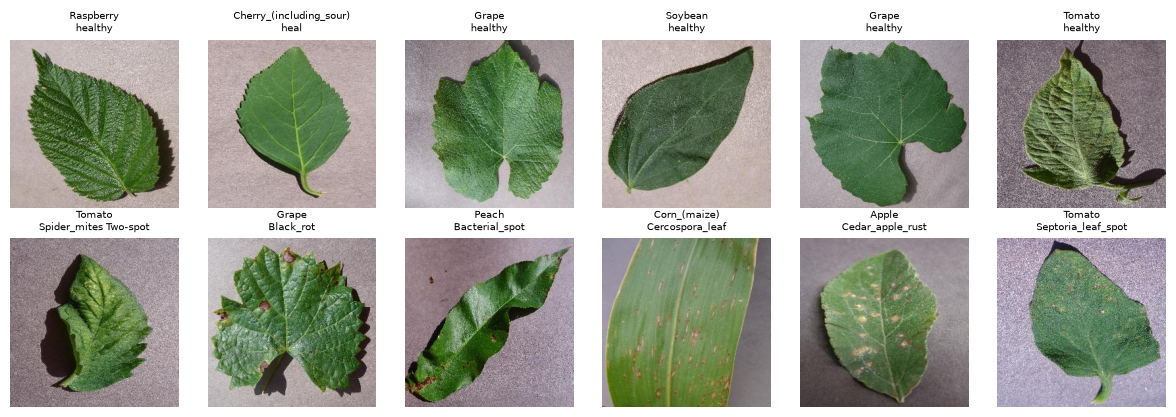

In [3]:
df["healthy"] = df["disease"].str.contains("healthy").astype(int)
print("hosts:", df["host"].nunique(), "| classes:", df["class_label"].nunique(), f"| healthy share {df['healthy'].mean():.1%}")
fig, axs = plt.subplots(2, 6, figsize=(12, 4.2))
for r, h in enumerate([1, 0]):
    for c, (_, row) in enumerate(df[df["healthy"] == h].sample(6, random_state=r).iterrows()):
        axs[r, c].imshow(Image.open(io.BytesIO(row["image"]["bytes"]))); axs[r, c].axis("off")
        axs[r, c].set_title(row["class_label"].replace("___", "\n")[:28], fontsize=7)
plt.tight_layout(); plt.show()

## 문제 하나 골라 보기: 잎 → 병에 걸렸나

색 히스토그램 (채널별 16칸) 으로 랜덤 포레스트. 데이터에 들어 있는 `split` 대로 나눈다. 기준선 = 가장 흔한 쪽.

In [4]:
from sklearn.ensemble import RandomForestClassifier

def leaf_features(image_bytes):
    """Per-channel 16-bin colour histogram + mean/std of one leaf photo (resized to 64x64)"""
    x = np.asarray(Image.open(io.BytesIO(image_bytes)).convert("RGB").resize((64, 64)), dtype=np.float32).reshape(-1, 3) / 255
    hist = [np.histogram(x[:, k], bins=16, range=(0, 1), density=True)[0] for k in range(3)]
    return np.r_[x.mean(0), x.std(0), np.concatenate(hist)]

X = np.stack([leaf_features(b["bytes"]) for b in df["image"]])
tr, te = (df["split"] == "train").values, (df["split"] != "train").values
for target in ["healthy", "class_idx"]:
    y = df[target].values
    m = RandomForestClassifier(400, random_state=0, n_jobs=-1).fit(X[tr], y[tr])
    pred = m.predict(X[te]); most = pd.Series(y[tr]).value_counts().idxmax()
    print(f"[{target}] baseline {np.mean(y[te] == most):.1%}  ->  random forest {np.mean(y[te] == pred):.1%}")

[healthy] baseline 69.4%  ->  random forest 88.6%


[class_idx] baseline 1.1%  ->  random forest 57.2%


**관찰**: '건강 / 병' 두 가지는 색만으로도 꽤 맞히지만 38종류는 어렵다. 이 데이터는 실험실에서 잎을 떼어 같은 배경에 찍은 사진이라, 밭에서 찍은 사진에서는 성능이 크게 떨어진다고 알려져 있다.

## 다른 문제로 바꿔 보기

- `leaf_grouped` 열: 같은 잎을 여러 번 찍은 사진이 있다면, 같은 잎이 학습 · 시험 양쪽에 들어가지 않게 나눠야 한다.
- 밭 전체를 드론으로 찍으면? 한 행 = 밭의 한 칸, 출력 = 병이 퍼진 비율.

### 나의 다섯 칸

아래 표를 직접 채워 보자. 위의 예시와 다르게 정해도 된다.

| 칸 | 내가 정한 것 |
|---|---|
| ① 한 행은 무엇? | |
| ② 입력 X (예측할 때 알 수 있는 것만) | |
| ③ 출력 y | |
| ④ 평가지표 | |
| ⑤ 기준선 | |